In [1]:
import pandas as pd
import numpy as np
from IPython.display import display

import sys
from pathlib import Path

# notebook 魔法：获取当前notebook工作目录
notebook_dir = Path.cwd()
# 向上一级作为项目根
project_root = notebook_dir.parent
sys.path.append(str(project_root))

%load_ext autoreload
%autoreload 2
'''
lr_churn.csv: 去除ID、二分类及流失标签映射、多分类热编码规避哑变量陷阱 31列
lr_feature_churn.csv: 去除ID、二分类及流失标签映射、多分类热编码规避哑变量陷阱、加入3个衍生特征去除冗余列 33列
XGBoost_churn.csv: 去除ID、二分类及流失标签映射、多分类热编码保留全部列 41列
XGBoost_feature_churn.csv: 去除ID、二分类及流失标签映射、多分类热编码保留全部列、加入3个衍生特征 46列
'''

'\nlr_churn.csv: 去除ID、二分类及流失标签映射、多分类热编码规避哑变量陷阱 31列\nlr_feature_churn.csv: 去除ID、二分类及流失标签映射、多分类热编码规避哑变量陷阱、加入3个衍生特征去除冗余列 33列\nXGBoost_churn.csv: 去除ID、二分类及流失标签映射、多分类热编码保留全部列 41列\nXGBoost_feature_churn.csv: 去除ID、二分类及流失标签映射、多分类热编码保留全部列、加入3个衍生特征 46列\n'

In [4]:
from src.model_utils import split_dataset,get_metrics

# 1.1 读取四份预处理好的数据集
df_lr_base = pd.read_csv("../data/processed/lr_churn.csv")
df_lr_enh = pd.read_csv("../data/processed/lr_feature_churn.csv")
df_xgb_base = pd.read_csv("../data/processed/XGBoost_churn.csv")
df_xgb_enh = pd.read_csv("../data/processed/XGBoost_feature_churn.csv")

SEED = 42
TEST_SIZE = 0.2

# 1.2 划分数据集
X_lr_base_tarin, X_lr_base_test, y_lr_base_tarin, y_lr_base_test = split_dataset(df_lr_base,test_size=TEST_SIZE,random_state=SEED)
X_lr_enh_tarin, X_lr_enh_test, y_lr_enh_tarin, y_lr_enh_test = split_dataset(df_lr_enh,test_size=TEST_SIZE,random_state=SEED)
X_xgb_base_tarin, X_xgb_base_test, y_xgb_base_tarin, y_xgb_base_test = split_dataset(df_xgb_base,test_size=TEST_SIZE,random_state=SEED)
X_xgb_enh_tarin, X_xgb_enh_test, y_xgb_enh_tarin, y_xgb_enh_test = split_dataset(df_xgb_enh,test_size=TEST_SIZE,random_state=SEED)

print('\n'+'-'*10+'数据集划分完成'+'-'*10)
print(f"训练集样本：{X_lr_base_tarin.shape[0]}，测试集样本：{X_lr_base_test.shape[0]}")


----------数据集划分完成----------
训练集样本：5634，测试集样本：1409


In [5]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
# 2. 模型训练
# 2.1 逻辑回归基线模型
lr_base = LogisticRegression(max_iter=1000, random_state=SEED)
lr_base.fit(X_lr_base_tarin,y_lr_base_tarin)
y_lr_base_pred = lr_base.predict(X_lr_base_test)
y_lr_base_prob = lr_base.predict_proba(X_lr_base_test)[:,1]
res_lr_base = get_metrics(y_lr_base_test,y_lr_base_pred,y_lr_base_prob)

# 2.2 逻辑回归-增加3个衍生特征
lr_enh = LogisticRegression(max_iter=1000, random_state=SEED)
lr_enh.fit(X_lr_enh_tarin,y_lr_enh_tarin)
y_lr_enh_pred = lr_enh.predict(X_lr_enh_test)
y_lr_enh_prob = lr_enh.predict_proba(X_lr_enh_test)[:,1]
res_lr_enh = get_metrics(y_lr_enh_test,y_lr_enh_pred,y_lr_enh_prob)

# 2.3 XGBoost(无衍生特征)
xgb_base = XGBClassifier(max_iter=1000, random_state=SEED)
xgb_base.fit(X_xgb_base_tarin,y_xgb_base_tarin)
y_xgb_base_pred = xgb_base.predict(X_xgb_base_test)
y_xgb_base_prob = xgb_base.predict_proba(X_xgb_base_test)[:,1]
res_xgb_base = get_metrics(y_xgb_base_test,y_xgb_base_pred,y_xgb_base_prob)

# 2.4 XGBoost(3个衍生特征)
xgb_enh = XGBClassifier(max_iter=1000, random_state=SEED)
xgb_enh.fit(X_xgb_enh_tarin,y_xgb_enh_tarin)
y_xgb_enh_pred = xgb_enh.predict(X_xgb_enh_test)
y_xgb_enh_prob = xgb_enh.predict_proba(X_xgb_enh_test)[:,1]
res_xgb_enh = get_metrics(y_xgb_enh_test,y_xgb_enh_pred,y_xgb_enh_prob)

c:\Users\16196\.conda\envs\churn-env\lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\16196\.conda\envs\churn-env\lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/prepr

In [7]:
res_table = pd.DataFrame({
    "LR-基线(无衍生)": res_lr_base,
    "LR-增强(含衍生)": res_lr_enh,
    "XGB-基线(无衍生)": res_xgb_base,
    "XGB-增强(含衍生)": res_xgb_enh
}).T
res_table.index.name = "模型"
display(res_table)

# 把表格保存到output
res_table.to_csv("../output/model_result.csv", encoding="utf-8-sig")
print("指标表格已保存至output/model_result.csv")

,AUC,Recall,Precision,F1
模型,,,,
LR-基线(无衍生),0.8427,0.5535,0.6530,0.5991
LR-增强(含衍生),0.8472,0.5348,0.6711,0.5952
XGB-基线(无衍生),0.8152,0.5107,0.5823,0.5442
XGB-增强(含衍生),0.8229,0.5294,0.6037,0.5641


指标表格已保存至output/model_result.csv


In [8]:
coef_df = pd.DataFrame({
    "feature": X_lr_enh_tarin.columns,
    "coef": lr_enh.coef_[0]
}).sort_values("coef", ascending=False)
display(coef_df)
coef_df.to_csv("../output/lr_enh_coef.csv", index=False, encoding="utf-8-sig")

,feature,coef
8,charge_ratio,1.329846
11,InternetService_Fiber optic,0.939316
10,MultipleLines_Yes,0.400090
5,PaperlessBilling,0.378013
28,PaymentMethod_Electronic check,0.329016
22,StreamingTV_Yes,0.326188
24,StreamingMovies_Yes,0.325860
1,SeniorCitizen,0.148222
2,Partner,0.056659
18,DeviceProtection_Yes,0.038524


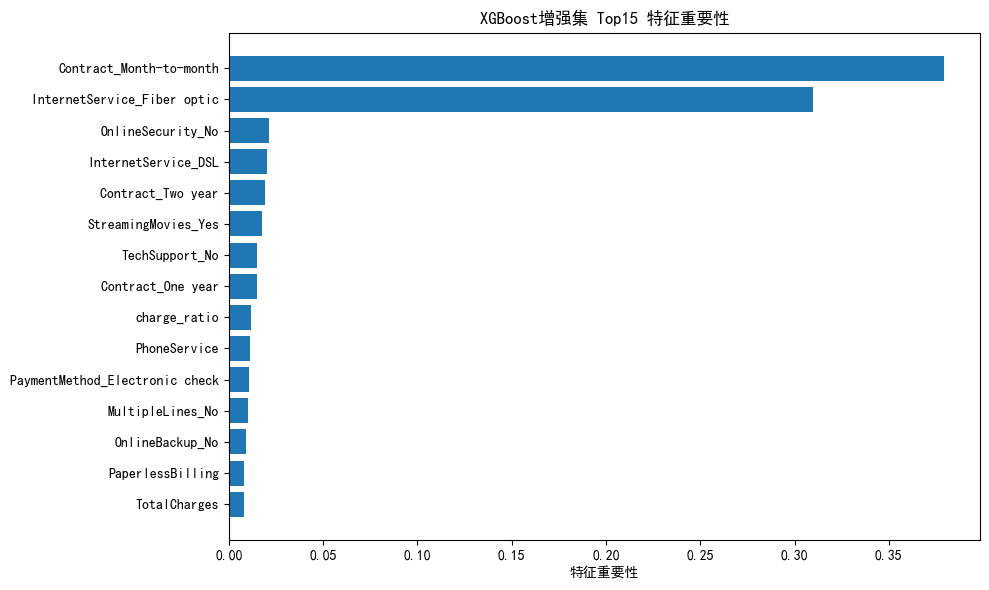

In [12]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

feat_importance = pd.DataFrame({
    "feature": X_xgb_enh_tarin.columns,
    "importance": xgb_enh.feature_importances_
}).sort_values("importance", ascending=False).head(15)

plt.figure(figsize=(10,6))
plt.barh(feat_importance["feature"], feat_importance["importance"])
plt.gca().invert_yaxis()
plt.xlabel("特征重要性")
plt.title("XGBoost增强集 Top15 特征重要性")
plt.tight_layout()
plt.savefig("../output/figures/xgb_importance.png", dpi=300, bbox_inches="tight")
plt.show()